Dataset Shape:
(520, 17)
Total Rows: 520
Total Columns: 17

First 10 Records:
   age gender polyuria polydipsia sudden_weight_loss weakness polyphagia  \
0   40   Male       No        Yes                 No      Yes         No   
1   58   Male       No         No                 No      Yes         No   
2   41   Male      Yes         No                 No      Yes        Yes   
3   45   Male       No         No                Yes      Yes        Yes   
4   60   Male      Yes        Yes                Yes      Yes        Yes   
5   55   Male      Yes        Yes                 No      Yes        Yes   
6   57   Male      Yes        Yes                 No      Yes        Yes   
7   66   Male      Yes        Yes                Yes      Yes         No   
8   67   Male      Yes        Yes                 No      Yes        Yes   
9   70   Male       No        Yes                Yes      Yes        Yes   

  genital_thrush visual_blurring itching irritability delayed_healing  \
0           

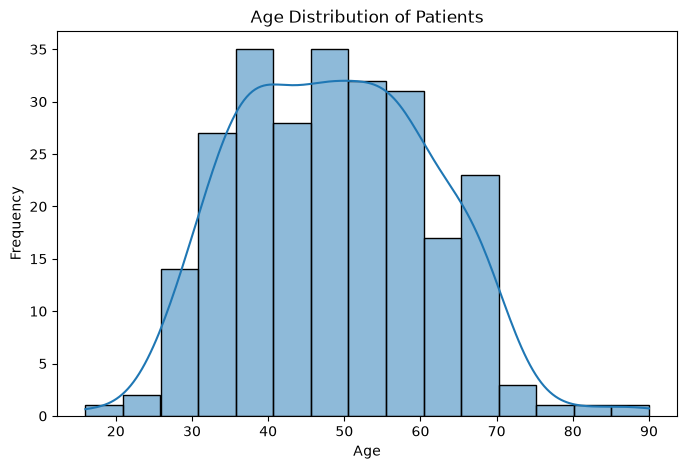

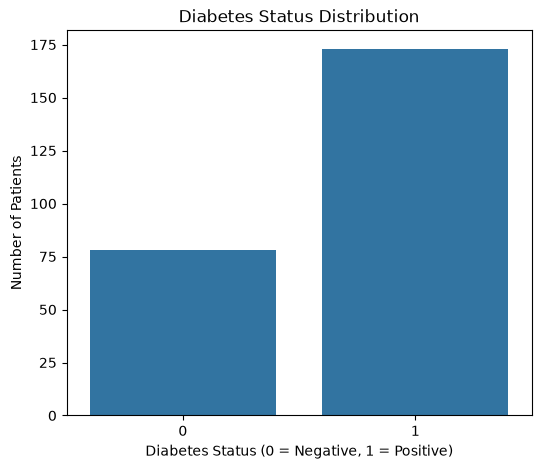

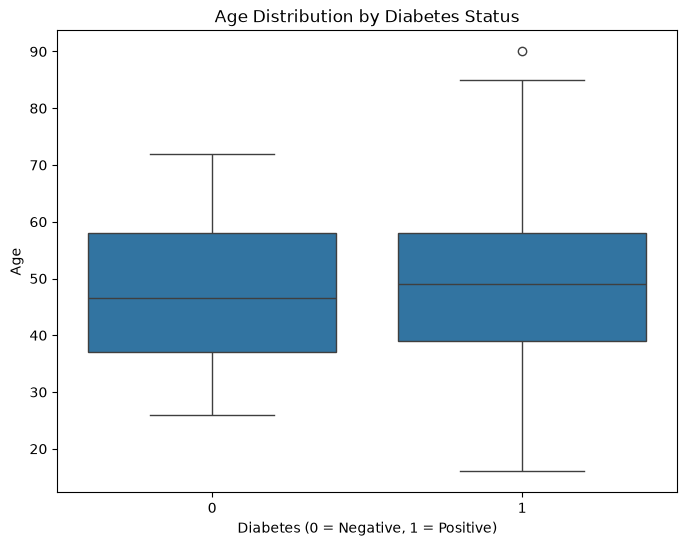

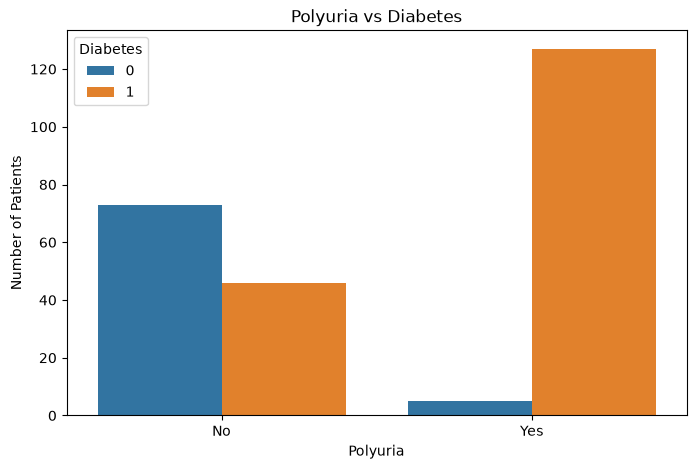

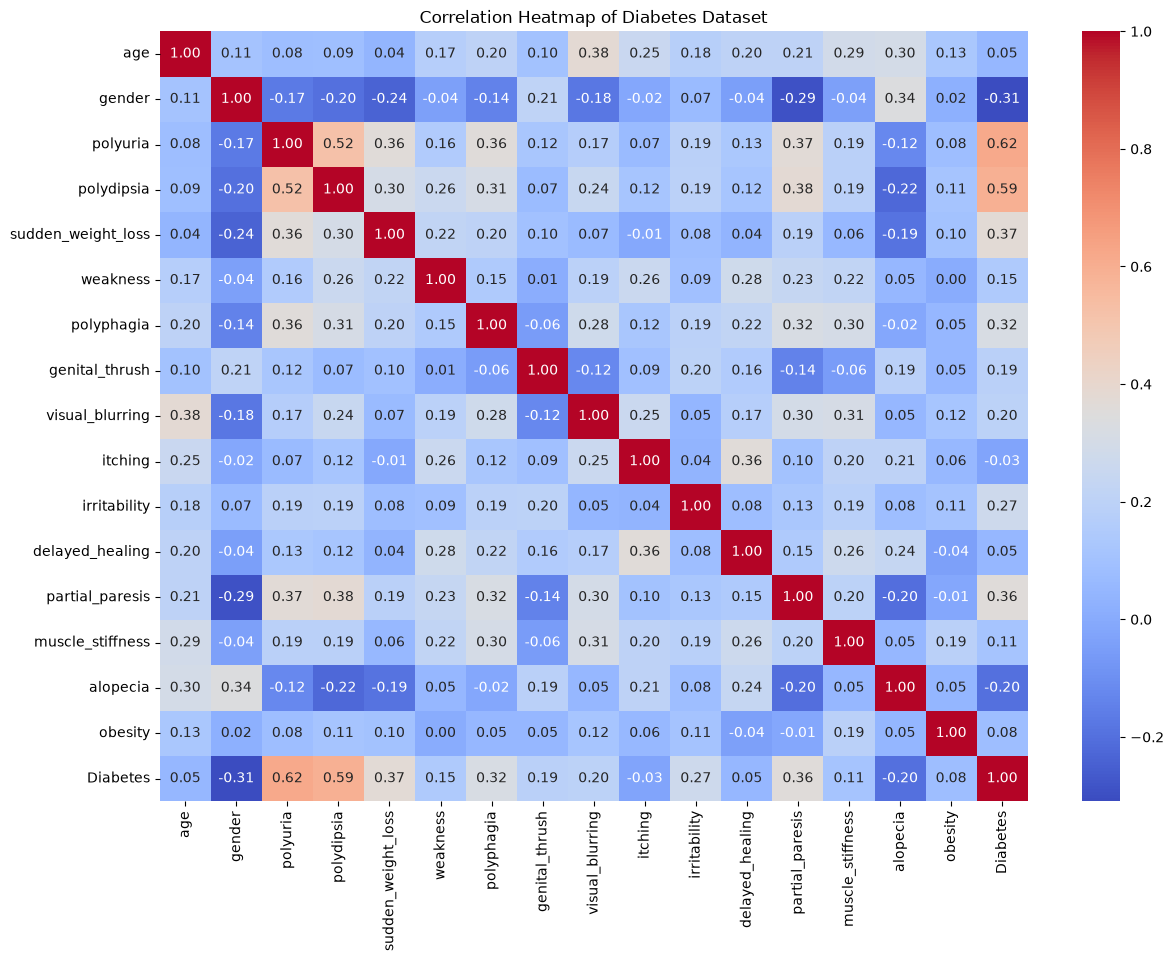


Average Age by Diabetes Status:
Diabetes
0    47.884615
1    49.306358
Name: age, dtype: float64

Patient Count by Diabetes Status:
Diabetes
1    173
0     78
Name: count, dtype: int64

Final Dataset Shape:
(251, 17)

Final Columns:
['age', 'gender', 'polyuria', 'polydipsia', 'sudden_weight_loss', 'weakness', 'polyphagia', 'genital_thrush', 'visual_blurring', 'itching', 'irritability', 'delayed_healing', 'partial_paresis', 'muscle_stiffness', 'alopecia', 'obesity', 'Diabetes']

Final Missing Values:
age                   0
gender                0
polyuria              0
polydipsia            0
sudden_weight_loss    0
weakness              0
polyphagia            0
genital_thrush        0
visual_blurring       0
itching               0
irritability          0
delayed_healing       0
partial_paresis       0
muscle_stiffness      0
alopecia              0
obesity               0
Diabetes              0
dtype: int64

Final Diabetes Distribution:
Diabetes
1    173
0     78
Name: count, dty

In [3]:

# 1. Import Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# 2. Collect Healthcare Dataset

diabetes = fetch_ucirepo(id=529)

X = diabetes.data.features
y = diabetes.data.targets

df = pd.concat([X, y], axis=1)

# 3. Display Dataset Shape

print("Dataset Shape:")
print(df.shape)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

# 4. Display First 10 Records

print("\nFirst 10 Records:")
print(df.head(10))

# 5. Dataset Information

print("\nDataset Information:")
df.info()

# 6. Descriptive Statistics

print("\nDescriptive Statistics:")
print(df.describe(include="all"))

# 7. Check Missing Values

print("\nMissing Values:")
print(df.isnull().sum())

# 8. Check Duplicate Records

print("\nDuplicate Records:")
print(df.duplicated().sum())

# 9. Remove Duplicate Records

df = df.drop_duplicates().copy()

# 10. Handle Missing Values

for col in df.columns:
    if df[col].dtype == "object":
        if df[col].isnull().any():
            df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

# 11. Rename Target Column

df.rename(columns={"class": "Diabetes"}, inplace=True)

# 12. Convert Target into 0 and 1

df["Diabetes"] = df["Diabetes"].astype(str).str.strip().str.lower().map({
    "negative": 0,
    "positive": 1
})

# 13. Diabetes Distribution

print("\nDiabetes Distribution:")
print(df["Diabetes"].value_counts())

# 14. Age Distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=15, kde=True)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution of Patients")
plt.show()

# 15. Diabetes Status Distribution

plt.figure(figsize=(6, 5))
sns.countplot(data=df, x="Diabetes")
plt.xlabel("Diabetes Status (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Patients")
plt.title("Diabetes Status Distribution")
plt.show()

# 16. Age Distribution by Diabetes Status

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="Diabetes", y="age")
plt.xlabel("Diabetes (0 = Negative, 1 = Positive)")
plt.ylabel("Age")
plt.title("Age Distribution by Diabetes Status")
plt.show()

# 17. Polyuria vs Diabetes

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="polyuria", hue="Diabetes")
plt.xlabel("Polyuria")
plt.ylabel("Number of Patients")
plt.title("Polyuria vs Diabetes")
plt.show()

# 18. Prepare Data for Correlation Analysis

df_corr = df.copy()

binary_columns = [
    "polyuria",
    "polydipsia",
    "sudden_weight_loss",
    "weakness",
    "polyphagia",
    "genital_thrush",
    "visual_blurring",
    "itching",
    "irritability",
    "delayed_healing",
    "partial_paresis",
    "muscle_stiffness",
    "alopecia",
    "obesity"
]

# Convert Yes/No into 1/0

for col in binary_columns:
    df_corr[col] = df_corr[col].astype(str).str.strip().str.lower().map({
        "yes": 1,
        "no": 0
    })

# Convert Gender into 1/0

df_corr["gender"] = df_corr["gender"].astype(str).str.strip().str.lower().map({
    "male": 1,
    "female": 0
})

# 19. Select Numerical Columns

numeric_cols = [
    "age",
    "gender",
    "polyuria",
    "polydipsia",
    "sudden_weight_loss",
    "weakness",
    "polyphagia",
    "genital_thrush",
    "visual_blurring",
    "itching",
    "irritability",
    "delayed_healing",
    "partial_paresis",
    "muscle_stiffness",
    "alopecia",
    "obesity",
    "Diabetes"
]

# 20. Calculate Correlation Matrix

corr = df_corr[numeric_cols].corr()

# 21. Correlation Heatmap

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Diabetes Dataset")
plt.show()

# 22. Average Age by Diabetes Status

print("\nAverage Age by Diabetes Status:")
print(df.groupby("Diabetes")["age"].mean())

# 23. Patient Count by Diabetes Status

print("\nPatient Count by Diabetes Status:")
print(df["Diabetes"].value_counts())

# 24. Final Dataset Shape

print("\nFinal Dataset Shape:")
print(df.shape)

# 25. Final Column Names

print("\nFinal Columns:")
print(df.columns.tolist())

# 26. Final Missing Values

print("\nFinal Missing Values:")
print(df.isnull().sum())

# 27. Final Diabetes Distribution

print("\nFinal Diabetes Distribution:")
print(df["Diabetes"].value_counts())

# 28. Save Cleaned Dataset

df.to_csv("cleaned_diabetes_data.csv", index=False)

print("\nCleaned Healthcare Dataset Saved Successfully!")
